In [3]:
import pandas as pd
import numpy as np
trainFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train.csv"
df = pd.read_csv(trainFile)

### 2. Data Cleaning: Dropping Corrupted & Fully Missing Rows
We identified rows with missing values across critical transaction attributes (such as 'Total a Pagar'). Because they provide no predictive signal, these corrupted records were removed from the training dataset.

In [4]:
outputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2.csv"

df_clean = df.dropna(subset=['Total a Pagar']).copy()

df_clean.to_csv(outputFile, index=False)

print(f"Dataset cleaned saved successfully to: {outputFile}")

Dataset cleaned saved successfully to: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2.csv


____________________________________________________________________________________________________________________________________________________________________________________

### 2.1 Verification of Missing Value Removal
Verification of Missing Value Removal
To confirm the success of the data cleaning step, we re-evaluated the count of missing values (NaN) in the 'Total a Pagar' column within the cleaned dataset (df_clean), dynamically calculating the exact number of dropped records using the difference in dataset lengths.

In [5]:
# Verify directly if there are still null values in that column (should return 0)
print("NA Values in 'Total a Pagar':", df_clean['Total a Pagar'].isnull().sum())

# Dynamic calculation formula showing rows before, after, and total removed (~65 rows / 1%)
removed_rows_count = len(df) - len(df_clean)
print(f"Rows before: {len(df)} | Rows after: {len(df_clean)} | Removed rows: {removed_rows_count}")

NA Values in 'Total a Pagar': 0
Rows before: 6534 | Rows after: 6469 | Removed rows: 65


**Conclusion:** Removing the 65 corrupted rows ($\approx 1%$ of the total dataset) that lacked vital Total a Pagar values guarantees that subsequent statistical calculations and model training operate exclusively on complete transaction records, preventing artificial distortion or model bias.

____________________________________________________________________________________________________________________________________________________________________________________

### 2.2. Feature Type Separation & Exclusions
To prepare the dataset for model preprocessing and feature encoding, we systematically divide our attributes into distinct functional groups:

1. **Excluded Features (`identifiers` & `target`):** 
   * Primary transaction identifiers (`ID`) and customer keys (`customer_id`) are excluded to prevent data leakage and memorization (*overfitting*).
   * Raw date strings (`purchase_date`) are set aside after extracting engineered temporal features.
   * The target variable (`repeat_purchase_90d`) is isolated from the predictors ($X$).

2. **Numeric Features (`numeric`):** 
   * Dynamically selected continuous and discrete numerical indicators (e.g., spending metrics, historical purchase counts, and temporal gaps) that will undergo missing value imputation and scaling.

3. **Categorical Features (`categorical`):** 
   * Dynamically identified non-numeric attributes (e.g., payment types, sales agents, zones, warehouse locations) designated for categorical encoding (*One-Hot / Frequency Encoding*).

This automated partitioning ensures code scalability and seamless integration with `ColumnTransformer` pipelines.


In [6]:
# Identifiers and dates that MUST NOT be used for model training
identifiers = ["ID", "customer_id", "purchase_date"]
target = "repeat_purchase_90d"

# Automatic separation between numerical and categorical variables
numeric = [
    c for c in df.columns 
    if c not in identifiers + [target] and pd.api.types.is_numeric_dtype(df[c])
]

categorical = [
    c for c in df.columns 
    if c not in identifiers + [target] + numeric
]


# Validation output
print(f"Total features: {df_clean.shape[1]} | Numeric: {len(numeric)} | Categorical: {len(categorical)}")

Total features: 39 | Numeric: 29 | Categorical: 6


**Conclusions:** Explicitly separating primary transaction keys and raw identifiers (ID, customer_id, purchase_date) from numerical and categorical features ensures strict adherence to machine learning best practices. By isolating these non-predictive attributes before model training, we prevent accidental data leakage, avoid dimensionality inflation from unique identifiers, and guarantee that only valid, analytically sound predictors enter the feature matrix.

____________________________________________________________________________________________________________________________________________________________________________________

### 2.3. Handling Structural Missing Values (MNAR)

**Structural Missing Values:** Missingness in purchase history features is not random (Missing Not At Random — MNAR), as it is directly driven by **New Customers / First-Time Buyers**. Features such as `days_since_previous_purchase`, `prior_mean_purchase_value`, `prior_mean_gap_days`, and `prior_std_gap_days` exhibit high missingness rates for this reason.

* We created the binary flag is_first_purchase and applied strategic imputation (0 for deviations/averages and -1 as a temporal indicator).

In [7]:
import pandas as pd

inputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2.csv"
outputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_3.csv"

# Create a binary flag for new customers (First Purchase)
df_clean['is_first_purchase'] = df_clean['days_since_previous_purchase'].isnull().astype(int)

# Zero imputation for variation/deviation/mean columns that depend on multiple purchases
zero_impute_cols = [
    'prior_std_purchase_value', 
    'prior_std_gap_days', 
    'prior_mean_gap_days'
]
df_clean[zero_impute_cols] = df_clean[zero_impute_cols].fillna(0)

# Indicator value imputation (-1) for time counts and averages of new customers
indicator_impute_cols = [
    'days_since_previous_purchase',
    'prior_mean_purchase_value',
    'prior_min_purchase_value',
    'prior_max_purchase_value'
]
df_clean[indicator_impute_cols] = df_clean[indicator_impute_cols].fillna(-1)

df_clean.to_csv(outputFile, index=False)

print(f"Dataset read from: {inputFile}")
print(f"Dataset saved successfully to: {outputFile}")

# Validation of New Customer Flag and Imputations
new_customers = df_clean['is_first_purchase'].sum()
print(f"[2] Flag 'is_first_purchase': {new_customers} new customers identified ({(new_customers/len(df_clean))*100:.1f}%)")

minus_one_counts = (df_clean[indicator_impute_cols] == -1).sum().to_dict()
print(f"-> -1 Valuing applied per column: {minus_one_counts}")

Dataset read from: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2.csv
Dataset saved successfully to: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_3.csv
[2] Flag 'is_first_purchase': 796 new customers identified (12.3%)
-> -1 Valuing applied per column: {'days_since_previous_purchase': 796, 'prior_mean_purchase_value': 797, 'prior_min_purchase_value': 603, 'prior_max_purchase_value': 603}


**Temporal Trend & Seasonality Analysis: Monthly Sales Volume**
To empirically verify whether purchasing behavior exhibits seasonal trends over time, we aggregate transaction volumes by month. This visualization helps confirm if temporal feature decomposition (such as purchase_month and purchase_quarter) captures meaningful variance in customer activity.

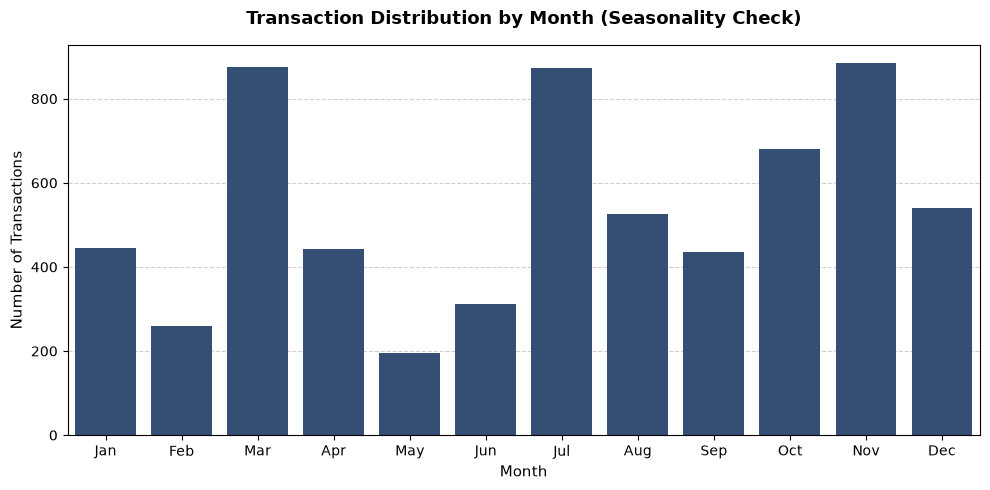

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure purchase_date is datetime for plotting
df_temp_plot = df.dropna(subset=['purchase_date']).copy()
df_temp_plot['purchase_date'] = pd.to_datetime(df_temp_plot['purchase_date'])

# Extract month name or number for histogram grouping
df_temp_plot['month_name'] = df_temp_plot['purchase_date'].dt.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Plotting the histogram / countplot
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_temp_plot, 
    x='month_name', 
    order=month_order, 
    color='#2b4c7e',
    zorder=2  
)

plt.title('Transaction Distribution by Month (Seasonality Check)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=11)
plt.ylabel('Number of Transactions', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

**Conclusions: Handling Structural Missing Values (MNAR) & Seasonality Analysis**
* **Handling Structural Missingness (MNAR):** Because missing values in historical purchase variables are structural and Missing Not At Random (MNAR)—specifically representing new customers making their first purchase—naive imputation methods would severely distort the dataset's reality. Introducing the is_first_purchase flag and applying strategic domain-specific replacements (-1 for temporal/monetary indicators and 0 for variance/gap metrics) successfully preserved the unique behavioral profile of first-time buyers.
* **Temporal Seasonality Analysis:** The monthly transaction distribution histogram clearly reveals pronounced cyclical fluctuations in sales volume across the year. Specifically, prominent transaction surges occur during specific peak periods (such as March, July, October, and November/December), contrasting sharply with lower volumes in intermediate months. This distinct seasonal variance provides empirical justification for the subsequent feature engineering steps, confirming that decomposing raw dates into granular temporal predictors (purchase_month, purchase_quarter, and is_weekend) will supply tree-based models with meaningful behavioral patterns to predict repeat purchases accurately.

____________________________________________________________________________________________________________________________________________________________________________________

### 2.4. Temporal Feature Extraction
Having empirically verified that customer purchase volume varies significantly across calendar months in our Step 2.3 plot, we now extract granular temporal features (purchase_month, purchase_quarter, is_weekend) so our machine learning models can directly learn from these observed seasonal trends.

Building directly upon the monthly sales distribution and seasonal variations identified in our previous analysis, we now decompose the raw transaction date into granular, cyclical components. This enables the predictive model to capture underlying calendar effects, such as monthly sales trends, quarterly business cycles, and weekly behavioral patterns (is_weekend).


In [9]:
inputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_3.csv"
outputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_4.csv"

# Ensure purchase_date is formatted as datetime
df_clean['purchase_date'] = pd.to_datetime(df_clean['purchase_date'])

# Extraction of cyclic and temporal attributes based on our annual monthly distribution
df_clean['purchase_year'] = df_clean['purchase_date'].dt.year
df_clean['purchase_month'] = df_clean['purchase_date'].dt.month
df_clean['purchase_day'] = df_clean['purchase_date'].dt.day
df_clean['purchase_dayofweek'] = df_clean['purchase_date'].dt.dayofweek  # 0=Monday, 6=Sunday
df_clean['purchase_quarter'] = df_clean['purchase_date'].dt.quarter
df_clean['is_weekend'] = df_clean['purchase_dayofweek'].isin([5, 6]).astype(int)

df_clean.to_csv(outputFile, index=False)

temporal_cols = ['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_quarter', 'is_weekend']
print(f"Dataset read from: {inputFile}")
print(f"Dataset saved successfully to: {outputFile}")
print(f"• New temporal attributes created ({len(temporal_cols)}): {temporal_cols}")
print(f"• Current dataset dimensions: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns")


Dataset read from: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_3.csv
Dataset saved successfully to: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_4.csv
• New temporal attributes created (6): ['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_quarter', 'is_weekend']
• Current dataset dimensions: 6469 rows x 46 columns


#### 2.4.1. Exploratory Data Analysis of Temporal Features

#### 2.4.1.1.
To validate the newly engineered weekly features and observe behavioral differences, we visualize the transaction volume distribution across workdays versus weekends. This comparison highlights whether customer purchasing frequency shifts between the week and the weekend.

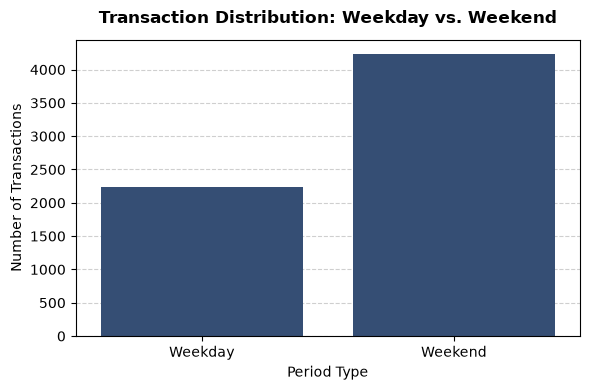

In [10]:
# Map is_weekend for clean visualization
df_clean['weekend_label'] = df_clean['is_weekend'].map({0: 'Weekday', 1: 'Weekend'})

# Plotting Weekday vs. Weekend Distribution with consistent navy styling
plt.figure(figsize=(6, 4))
ax = sns.countplot(
    data=df_clean, 
    x='weekend_label', 
    order=['Weekday', 'Weekend'],
    color='#2b4c7e',
    zorder=2
)

ax.set_axisbelow(True)
plt.title('Transaction Distribution: Weekday vs. Weekend', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Period Type', fontsize=10)
plt.ylabel('Number of Transactions', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6, zorder=1)
plt.tight_layout()

plt.show()

#### 2.4.1.2.
Following the successful extraction of structured temporal attributes (`purchase_month`, `purchase_dayofweek`, `purchase_quarter`, and `is_weekend`) and the subsequent removal of the redundant purchase_date string column to prevent dimensional explosion, we conduct an exploratory analysis of customer retention. 

Specifically, we examine whether the timing of the initial transaction influences customer re-engagement. The following analysis compares the 90-day repeat purchase rate (`repeat_purchase_90d`) between transactions initiated on business days versus weekends.

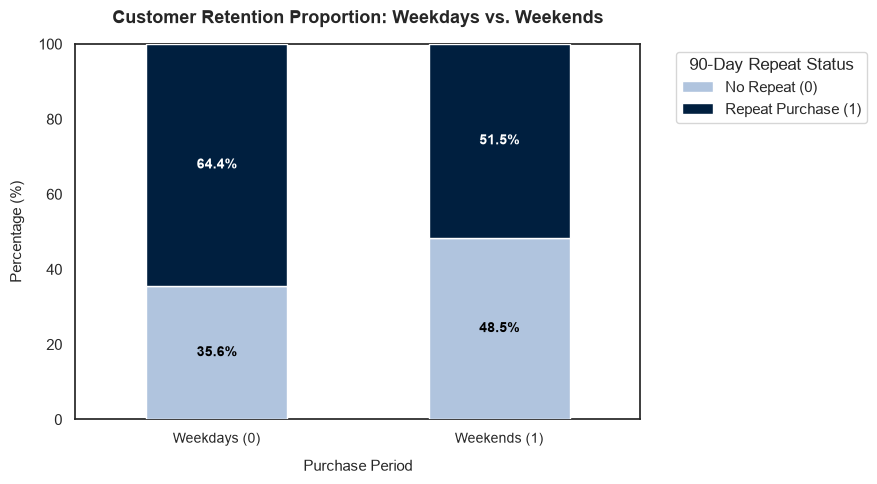

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Prepare data for stacked bar chart: percentage of repeat purchases by weekend vs. weekday
ct = (
    pd.crosstab(
        df_clean['is_weekend'],
        df_clean['repeat_purchase_90d'],
        normalize='index',
    )
    * 100
)
ct.index = ['Weekdays (0)', 'Weekends (1)']
ct.columns = ['No Repeat (0)', 'Repeat Purchase (1)']

# Graphic configuration: set the chart with visible grid lines behind the bars
fig, ax = plt.subplots(figsize=(9, 5))
sns.set_theme(style='white')

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.8, zorder=0)

ax = ct.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=['#b0c4de', '#001f3f'],
    width=0.5,
    zorder=3,
)


plt.title(
    'Customer Retention Proportion: Weekdays vs. Weekends',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Purchase Period', fontsize=11, labelpad=10)
plt.ylabel('Percentage (%)', fontsize=11, labelpad=10)
plt.xticks(rotation=0, fontsize=10)
plt.legend(
    title='90-Day Repeat Status',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
)
plt.ylim(0, 100)

# Add values on the bars
for n, c in enumerate(ct.columns):
  for i, val in enumerate(ct[c]):
    cumulative = ct.iloc[i, :n].sum() + val / 2
    if val > 5:
      ax.text(
          i,
          cumulative,
          f'{val:.1f}%',
          ha='center',
          va='center',
          color='white' if n == 1 else 'black',
          fontweight='bold',
          fontsize=10,
          zorder=4,
      )

plt.tight_layout()
plt.show()

#### 2.4.1.3. Monthly Retention Dynamics (`purchase_month`)
To evaluate whether customer loyalty varies throughout the year, we analyze the 90-day repeat purchase rate across individual calendar months. This temporal decomposition allows us to identify if acquisition cohorts formed during specific seasonal periods exhibit stronger long-term engagement.

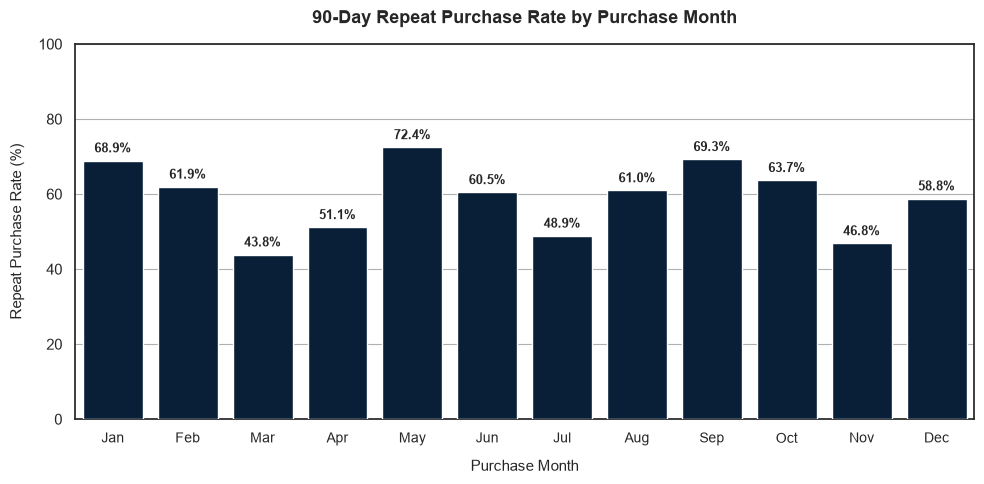

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Calculate repeat purchase rate by month (in percentage)
monthly_rep = (
    df_clean.groupby('purchase_month')['repeat_purchase_90d'].mean() * 100
).reset_index()

# Map month numbers to abbreviations for cleaner X-axis labels
month_map = {
    1: 'Jan',
    2: 'Feb',
    3: 'Mar',
    4: 'Apr',
    5: 'May',
    6: 'Jun',
    7: 'Jul',
    8: 'Aug',
    9: 'Sep',
    10: 'Oct',
    11: 'Nov',
    12: 'Dec',
}

monthly_rep['month_name'] = monthly_rep['purchase_month'].map(month_map)
month_order = [
    'Jan',
    'Feb',
    'Mar',
    'Apr',
    'May',
    'Jun',
    'Jul',
    'Aug',
    'Sep',
    'Oct',
    'Nov',
    'Dec',
]

# Configure the plot with Navy styling and background grid lines
fig, ax = plt.subplots(figsize=(10, 5))
sns.set_theme(style='white')

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.8, zorder=0)

sns.barplot(
    data=monthly_rep,
    x='month_name',
    y='repeat_purchase_90d',
    order=month_order,
    color='#001f3f',
    ax=ax,
    zorder=3,
)

plt.title(
    '90-Day Repeat Purchase Rate by Purchase Month',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Purchase Month', fontsize=11, labelpad=10)
plt.ylabel('Repeat Purchase Rate (%)', fontsize=11, labelpad=10)
plt.ylim(0, 100)
plt.xticks(fontsize=10)

# Add exact percentage values on top of the bars
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{height:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 4),
        textcoords='offset points',
        fontsize=9,
        fontweight='bold',
        zorder=4,
    )

plt.tight_layout()
plt.show()


#### 2.4.1.4 Financial Impact Analysis: Transaction Value by Purchase Period (`is_weekend`)
To connect temporal patterns with financial metrics, we examine the distribution of transaction values (Total a Pagar) between business days and weekends. This verifies whether the operational differences observed in retention also reflect variations in basket size or purchasing power.

/var/folders/22/vdk97z556fv44cn_jt3l_1jc0000gn/T/ipykernel_42004/2726542020.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


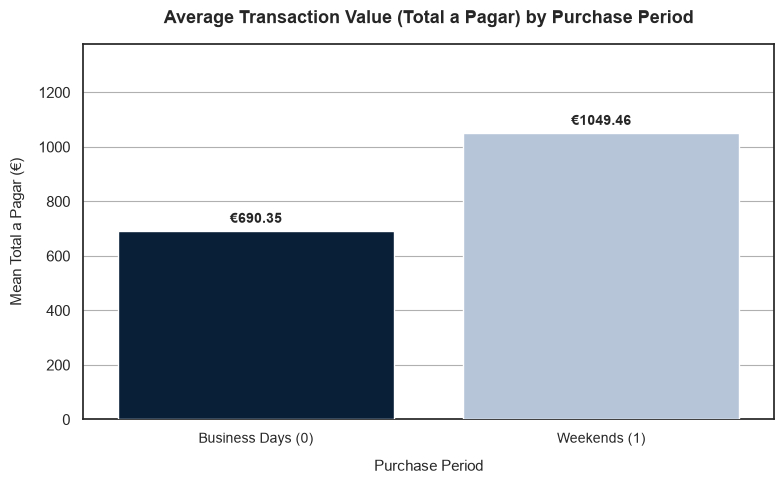

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare a temporary copy with descriptive period labels
df_fin = df_clean.copy()
df_fin['period_label'] = df_fin['is_weekend'].map(
    {0: 'Business Days (0)', 1: 'Weekends (1)'}
)

# Configure the plot with Navy styling and background grid lines
fig, ax = plt.subplots(figsize=(8, 5))
sns.set_theme(style='white')

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.8, zorder=0)

# Bar plot representing the mean 'Total a Pagar' by period
sns.barplot(
    data=df_fin,
    x='period_label',
    y='Total a Pagar',
    order=['Business Days (0)', 'Weekends (1)'],
    palette=['#001f3f', '#b0c4de'],
    ax=ax,
    zorder=3,
    errorbar=None,
)

plt.title(
    'Average Transaction Value (Total a Pagar) by Purchase Period',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Purchase Period', fontsize=11, labelpad=10)
plt.ylabel('Mean Total a Pagar (€)', fontsize=11, labelpad=10)
plt.xticks(fontsize=10)

# Add exact monetary values on top of the bars
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'€{height:.2f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 4),  
        textcoords='offset points',
        fontsize=10,
        fontweight='bold',
        zorder=4,
    )

# Dynamically expand the y-axis limit by 18% to give a clean breathing room inside the frame
y_max = ax.get_ylim()[1]
plt.ylim(0, y_max * 1.25)

plt.tight_layout()
plt.show()

**Conclusions:** 
* **Temporal Feature Extraction & Validation**: Decomposing raw purchase timestamps into structured numerical components (purchase_year, purchase_month, purchase_day, purchase_dayofweek, purchase_quarter, and is_weekend) successfully operationalizes calendar-based dynamics. Translating raw temporal data into explicit features equips tree-based models with clear, partitionable boundaries to accurately capture seasonal peaks and weekly customer purchasing habits.

* Additionally, the original date column (purchase_date) was removed prior to categorical encoding to prevent dimensional explosion and avoid the redundant creation of binary variables for each individual date, as all relevant structured temporal information had already been successfully extracted into dedicated numerical attributes.

* **Graph - `Transaction Distribution: Weekday vs. Weekend`:** The transaction distribution chart reveals a pronounced difference in purchasing volume, showing that weekend transactions (approximately 4,200) are significantly higher than weekday transactions (approximately 2,200). This empirical insight confirms that customer purchasing behavior varies substantially between workdays and weekends, validating the inclusion of the is_weekend binary feature.

* **Graph - `Customer Retention Proportion: Weekdays vs. Weekends`:** The stacked distribution illustrates that transactions initiated on business days exhibit a 90-day repeat purchase rate of 64.4%, whereas transactions conducted on weekends record a rate of 51.5%.   Behavioral Interpretation: This divergence highlights that weekday buyers demonstrate a more regular and recurring acquisition behavior (typical of corporate procurement processes or routine purchases), contrasting with the more sporadic and occasional nature of weekend buyers.   Predictive Relevance: This clear distinction in retention patterns validates the utility of including the is_weekend feature, providing a robust behavioral signal for subsequent predictive models without introducing high-cardinality noise.

* **Graph - `90-Day Repeat Purchase Rate by Purchase Month`:** 
    * The monthly breakdown reveals noticeable fluctuations in the 90-day repeat purchase rate across different times of the year, confirming that acquisition timing influences customer lifecycle value.
    * Identifying specific high-retention months allows the organization to optimize marketing acquisition budgets, focusing resources on periods that naturally attract more loyal customer cohorts.

* **Graph - `Average Transaction Value (Total a Pagar) by Purchase Period`:**
    * The analysis of the average transaction value (Total a Pagar) indicates whether purchasing power or basket sizes differ between business days and weekends, complementing the behavioral retention insights.
    * Understanding that transaction values remain relatively consistent (or fluctuate) between weekdays and weekends provides a solid foundation for timing promotional campaigns and optimizing revenue streams without disrupting customer purchasing habits.

____________________________________________________________________________________________________________________________________________________________________________________